# Distribución de los errores

Primer análisis de la Etapa A: forma de la distribución del error de pronóstico (asimetría, normalidad y valores atípicos)
para las cuatro variables: temperatura, humedad relativa, punto de rocío y velocidad del viento.

Se parte del dataset limpio que exporta `relaciones-bivariadas.ipynb` (secc. 1), que ya excluye las estaciones `sin_meteo`
y los valores inválidos. El error se define como **pronosticado − observado**, igual que en la secc. 8 de ese notebook:
un error positivo indica que el pronóstico **sobreestima** la variable (signo opuesto al de la consigna).

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import CenteredNorm, Normalize
from scipy import stats
from utils import (AZUL, NARANJA, GRIS_TEXTO, SECUENCIAL, DIVERGENTE,
                   aplicar_estilo, cargar_mediciones_limpias)

In [2]:
PROCESSED = '../data/processed/'
OUT = '../data/out/distribucion/'

# Paleta y estilo de los gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}  # se exportan todas al final

## 1. Carga de los datos

In [3]:
mp = cargar_mediciones_limpias()

# (columna de error, nombre, unidad)
ERRORES = [
    ('error_temp_c', 'Temperatura', '°C'),
    ('error_rh_pct', 'Humedad relativa', 'puntos de %'),
    ('error_dewpoint_c', 'Punto de rocío', '°C'),
    ('error_windspeed_kmh', 'Velocidad del viento', 'km/h'),
]
print(f'{len(mp):,} filas, {mp["station_id"].nunique()} estaciones')
mp[[col for col, *_ in ERRORES]].describe().round(2)

217,297 filas, 345 estaciones


,error_temp_c,error_rh_pct,error_dewpoint_c,error_windspeed_kmh
count,186760.00,178718.00,180874.00,186015.00
mean,0.07,-0.23,-0.01,2.93
std,1.48,7.65,1.29,5.79
min,-13.89,-77.96,-14.73,-53.11
25%,-0.83,-4.47,-0.70,-0.76
50%,0.00,-0.01,-0.03,2.25
75%,0.84,4.31,0.69,6.45
max,13.89,73.86,11.27,40.23


## 2. QQ-plot contra la normal

Cada punto compara un cuantil del error con el mismo cuantil de una normal estándar. Si el error fuera normal, los puntos
caerían sobre una recta. La recta de referencia (naranja) pasa por los cuartiles P25 y P75, como `qqline` de R:
así refleja el centro de la distribución y no se deja arrastrar por las colas, que es justamente lo que se quiere evaluar.
Su pendiente es un desvío robusto (RIC / 1,349).

Cómo leer los desvíos de la recta:

- **Colas pesadas** (curtosis > 0): los extremos se alejan de la recta hacia afuera, por debajo a la izquierda y por encima
  a la derecha (forma de S invertida). Hay más errores grandes de los que predice una normal.
- **Asimetría**: si solo una de las colas se separa, esa es la cola larga (a la derecha, asimetría positiva).
- **Escalones**: el pronóstico de temperatura viene en °F enteros y el de viento en mph enteras, así que sus errores
  toman valores discretos y el QQ-plot se ve escalonado.

Con ~180 mil pares por variable no se grafican todos los puntos: se toman 1.000 cuantiles equiespaciados en el centro
y 200 por cola, espaciados logarítmicamente hasta el valor mínimo y el máximo, para que los extremos no se pierdan.

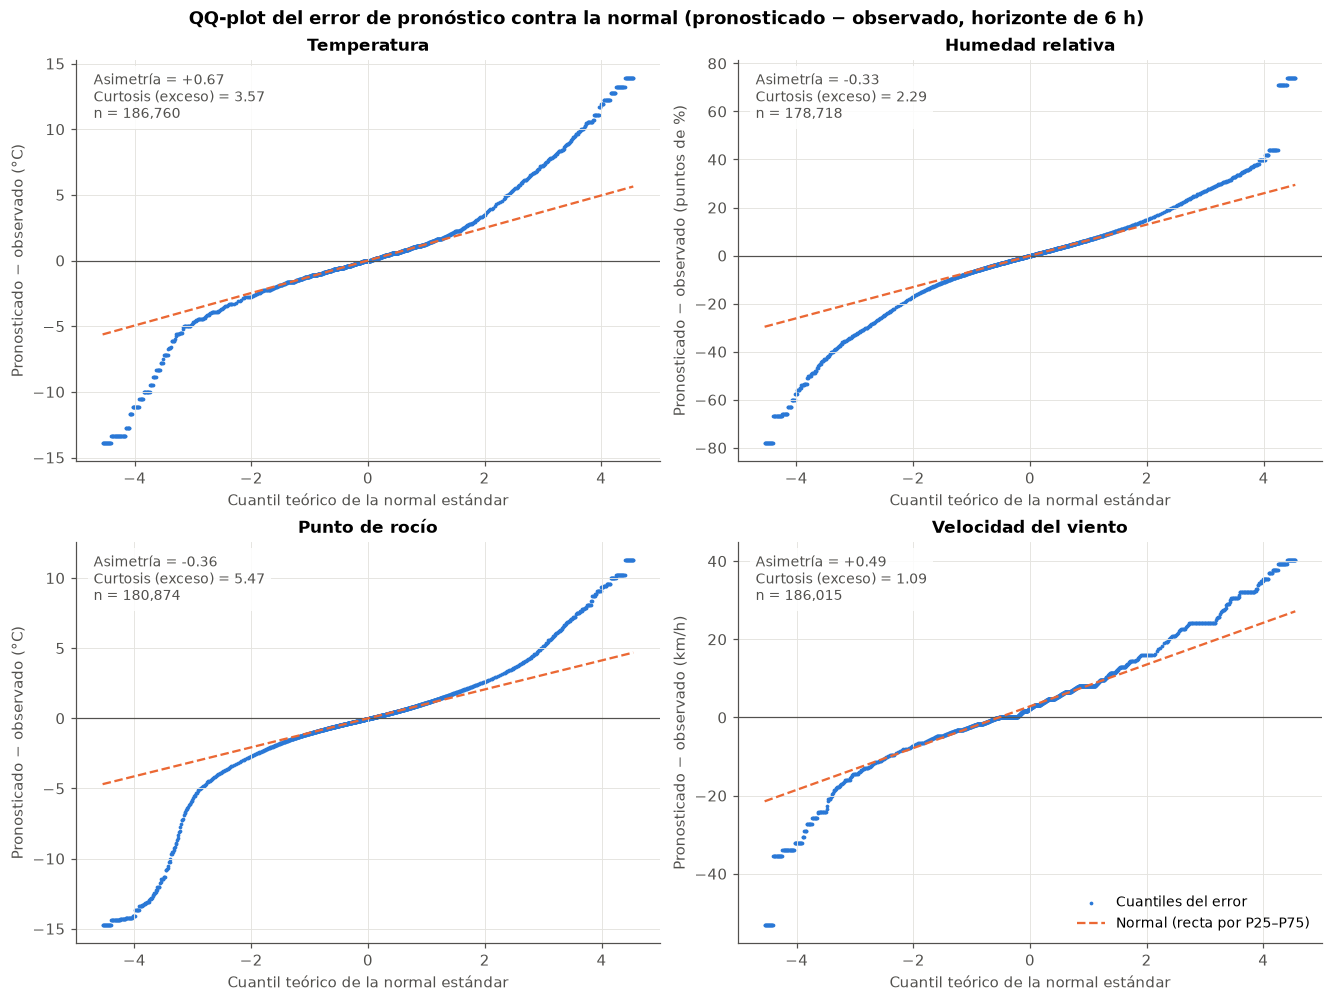

,n,Asimetría,Curtosis (exceso)
Temperatura,186760,0.67,3.57
Humedad relativa,178718,-0.33,2.29
Punto de rocío,180874,-0.36,5.47
Velocidad del viento,186015,0.49,1.09


In [4]:
def cuantiles_qq(e, n_centro=1000, n_cola=200, p_cola=0.01):
    """Cuantiles empíricos y teóricos (normal estándar) en una grilla densa en el centro y logarítmica en las colas."""
    e = np.sort(e.dropna().to_numpy())
    n = len(e)
    cola = np.geomspace(0.5 / n, p_cola, n_cola)
    p = np.unique(np.concatenate([cola, np.linspace(p_cola, 1 - p_cola, n_centro), 1 - cola]))
    # Se toma el valor observado (sin interpolar) para conservar los escalones de los errores discretos
    muestral = e[np.clip(np.floor(p * n).astype(int), 0, n - 1)]
    return stats.norm.ppf(p), muestral


fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
filas = {}
for ax, (col, nombre, unidad) in zip(axes.flat, ERRORES):
    e = mp[col].dropna()
    teorico, muestral = cuantiles_qq(e)
    q25, q75 = e.quantile([0.25, 0.75])
    z25, z75 = stats.norm.ppf([0.25, 0.75])
    pendiente = (q75 - q25) / (z75 - z25)
    ordenada = q25 - pendiente * z25
    filas[nombre] = {'n': len(e), 'Asimetría': stats.skew(e), 'Curtosis (exceso)': stats.kurtosis(e)}

    ax.axhline(0, color=GRIS_TEXTO, lw=0.8)
    ax.scatter(teorico, muestral, s=6, color=AZUL, linewidths=0, label='Cuantiles del error')
    lim = np.array([teorico.min(), teorico.max()])
    ax.plot(lim, ordenada + pendiente * lim, color=NARANJA, lw=1.5, ls='--', label='Normal (recta por P25–P75)')
    ax.text(0.03, 0.97, f'Asimetría = {filas[nombre]["Asimetría"]:+.2f}\n'
                        f'Curtosis (exceso) = {filas[nombre]["Curtosis (exceso)"]:.2f}\nn = {len(e):,}',
            transform=ax.transAxes, va='top', fontsize=9, color=GRIS_TEXTO,
            bbox=dict(fc='white', ec='none', alpha=0.85))
    ax.set(title=nombre, xlabel='Cuantil teórico de la normal estándar',
           ylabel=f'Pronosticado − observado ({unidad})')
axes[1, 1].legend(loc='lower right', frameon=False, fontsize=9)
fig.suptitle('QQ-plot del error de pronóstico contra la normal (pronosticado − observado, horizonte de 6 h)',
             fontweight='bold')
figuras['01_qqplot_error'] = fig
plt.show()

tabla_forma = pd.DataFrame(filas).T
tabla_forma['n'] = tabla_forma['n'].astype(int)
tabla_forma.round(2)

Ninguna de las cuatro distribuciones es normal: todas siguen la recta en el centro (aproximadamente entre −1,5 y +1,5
desvíos) y se separan en las colas, siempre hacia afuera. Son distribuciones con **colas pesadas** (curtosis en exceso
positiva en las cuatro): los errores grandes son bastante más frecuentes de lo que predice una normal con el mismo centro
y dispersión. Por eso el RMSE de la fig. 08 de `relaciones-bivariadas.ipynb` queda tan por encima del MAE.

- **Temperatura**: la cola derecha es mucho más larga que la izquierda (asimetría +0,67). Los errores grandes son sobre todo
  **sobreestimaciones**: el pronóstico supera a la observación por 5 °C o más con más frecuencia que a la inversa.
  Los escalones corresponden al paso de 1 °F (5/9 °C) del pronóstico.
- **Humedad relativa**: ocurre lo contrario, la cola larga es la izquierda (asimetría −0,33), es decir, **subestimaciones**
  grandes. Es coherente con la fig. 10: el pronóstico no llega a la saturación cuando la HR observada es alta. Los saltos
  aislados de ±70 puntos en los extremos son pocos pares y parecen fallas de medición más que del modelo.
- **Punto de rocío**: es la variable con el centro más ajustado y la mayor curtosis (5,47). La cola izquierda cae de golpe
  a partir de −3 desvíos, con errores de −5 a −15 °C: observaciones de rocío muy por encima del pronóstico, candidatas a
  revisar en el análisis de atípicos.
- **Velocidad del viento**: toda la nube está desplazada hacia arriba: la recta corta el eje vertical en ~+2,8 km/h, cerca
  del sesgo de +2,9 km/h. Las colas son las menos pesadas (curtosis 1,09), pero la derecha es más larga (asimetría +0,49):
  predominan las sobreestimaciones grandes. Los escalones son de 1 mph y el tramo plano en 0 corresponde a las calmas
  (pronóstico y observación en 0).

## 3. Errores extremos: ¿falla del sensor o del modelo?

Un error extremo puede venir de dos fuentes muy distintas:

- **Falla del sensor** (o de la instalación): la observación está mal y el pronóstico no. Hay que filtrarla antes de evaluar
  el modelo, porque infla el error sin decir nada de él.
- **Falla del modelo**: la observación es real y el pronóstico no anticipó el fenómeno (una tormenta, un frente). Es
  justamente lo que interesa analizar.

### Qué se considera extremo

Se usa el criterio de Tukey para atípicos **lejanos**: un error es extremo si queda a más de **3 RIC** por debajo de P25 o
por encima de P75 de su variable. Se usa el RIC y no el desvío estándar porque el desvío está inflado por las mismas colas
pesadas que muestra el QQ-plot. Con 3 RIC en lugar de 1,5 RIC quedan solo los casos realmente anómalos
(en una normal serían 2 de cada millón).

In [5]:
mp = mp.sort_values(['station_id', 'fcst_target_timestamp']).reset_index(drop=True)

filas = {}
for col, nombre, unidad in ERRORES:
    q25, q75 = mp[col].quantile([0.25, 0.75])
    inferior, superior = q25 - 3 * (q75 - q25), q75 + 3 * (q75 - q25)
    mp[f'extremo_{col}'] = mp[col].lt(inferior) | mp[col].gt(superior)
    n = mp[col].notna().sum()
    filas[nombre] = {'Unidad': unidad, 'Límite inferior': inferior, 'Límite superior': superior,
                     'Extremos': mp[f'extremo_{col}'].sum(),
                     '% por debajo': mp[col].lt(inferior).sum() / n * 100,
                     '% por encima': mp[col].gt(superior).sum() / n * 100}

tabla_umbrales = pd.DataFrame(filas).T
tabla_umbrales.round(2)

,Unidad,Límite inferior,Límite superior,Extremos,% por debajo,% por encima
Temperatura,°C,-5.84,5.85,920,0.048726,0.443885
Humedad relativa,puntos de %,-30.783291,30.624178,471,0.221019,0.042525
Punto de rocío,°C,-4.878889,4.866667,719,0.231653,0.165861
Velocidad del viento,km/h,-22.38,28.076,122,0.025804,0.039782


### La humedad relativa observada no es una medición independiente

Antes de cruzar variables para detectar sensores fallados hay que saber qué se mide realmente. La HR observada coincide
con la que se calcula a partir de la temperatura y el punto de rocío observados (fórmula de Magnus), así que la API la
**deriva** de esas dos. Consecuencia: no se puede usar la HR para validar el higrómetro, y una falla del sensor de humedad
aparece a la vez en el punto de rocío y en la HR.

In [6]:
def hr_magnus(t, td):
    """Humedad relativa (%) a partir de la temperatura y el punto de rocío (°C), fórmula de Magnus."""
    def presion_vapor(x):
        return 6.112 * np.exp(17.62 * x / (243.12 + x))
    return 100 * presion_vapor(td) / presion_vapor(t)


diferencia = (mp['obs_rh_pct'] - hr_magnus(mp['obs_temp_c'], mp['obs_dewpoint_c'])).abs()
print(f'Diferencia entre la HR observada y la calculada: máxima {diferencia.max():.2f} puntos '
      f'en {diferencia.notna().sum():,} observaciones')

Diferencia entre la HR observada y la calculada: máxima 0.02 puntos en 178,677 observaciones


### Criterios para separar sensor y modelo

Cada error extremo se asigna a la **primera** clase que cumple, en este orden:

1. **Valor congelado** (sensor): la observación forma parte de una racha de 6 o más reportes seguidos de la estación
   con exactamente el mismo valor. Un sensor real registra pequeñas variaciones de hora a hora; un valor fijo durante
   6 horas indica que el sensor o la transmisión se trabó. En el viento no cuentan las rachas en 0 (las calmas
   nocturnas son reales) y en la HR se usa la racha de la temperatura o del punto de rocío, de las que se deriva.
2. **Estación con falla persistente** (sensor): la estación tiene 10 % o más de sus pares de esa variable como extremos,
   unas 20 veces la tasa global. Un modelo no falla de forma extrema todos los días en un único punto y no en sus
   vecinos: es un sensor descalibrado, mal instalado (al sol, sin ventilación, bajo un árbol) o con deriva.
3. **Evento compartido** (modelo): al menos una estación vecina (a 50 km o menos) tiene un error extremo **del mismo
   signo a la misma hora**, sin ser ella misma un caso de las clases 1 o 2. Dos sensores independientes rara vez fallan
   igual y a la vez: es un fenómeno meteorológico real que el pronóstico no anticipó.
4. **Aislado** (ambiguo): hay vecinas con dato a esa hora pero ninguna acompaña. Puede ser una falla puntual del sensor o
   un fenómeno muy local, como una tormenta aislada; con estos datos no se pueden separar.
5. **Sin vecinos** (indeterminado): ninguna estación a 50 km tiene dato a esa hora.

In [7]:
N_REPETIDOS = 6        # reportes seguidos con el mismo valor para considerar el sensor congelado
PCT_PERSISTENTE = 10   # % de extremos de una estación a partir del cual la falla se considera persistente
PCT_CONGELADO = 25     # % de observaciones congeladas para listar la estación como sospechosa
N_MIN_PARES = 50       # pares mínimos de una estación para calcular sus porcentajes
RADIO_KM = 50          # radio de vecindad


def congelado(obs, ignorar_cero=False):
    """True si la observación forma parte de una racha de N_REPETIDOS o más reportes seguidos iguales en su estación."""
    s = obs.dropna()
    estacion = mp.loc[s.index, 'station_id']
    racha = s.ne(s.groupby(estacion).shift()).cumsum()  # cambia de número en cada valor distinto o estación nueva
    resultado = s.groupby(racha).transform('size').ge(N_REPETIDOS)
    if ignorar_cero:
        resultado &= s.ne(0)
    return resultado.reindex(obs.index, fill_value=False)


mp['congelado_error_temp_c'] = congelado(mp['obs_temp_c'])
mp['congelado_error_dewpoint_c'] = congelado(mp['obs_dewpoint_c'])
mp['congelado_error_rh_pct'] = mp['congelado_error_temp_c'] | mp['congelado_error_dewpoint_c']
mp['congelado_error_windspeed_kmh'] = congelado(mp['obs_windspeed_kmh'], ignorar_cero=True)

# Resumen por estación y variable
atributos = mp.groupby('station_id')[['estado', 'red']].first()
filas = []
for col, nombre, _ in ERRORES:
    g = mp[mp[col].notna()].groupby('station_id')
    t = pd.DataFrame({'Pares': g.size(), 'Extremos': g[f'extremo_{col}'].sum(),
                      'Error mediano': g[col].median(), '% congelado': g[f'congelado_{col}'].mean() * 100})
    t['% extremos'] = t['Extremos'] / t['Pares'] * 100
    t = t[t['Pares'] >= N_MIN_PARES]
    persistentes = t.index[t['% extremos'] >= PCT_PERSISTENTE]
    mp[f'persistente_{col}'] = mp['station_id'].isin(persistentes)
    filas.append(t.assign(Variable=nombre).reset_index())
por_estacion = pd.concat(filas, ignore_index=True).join(atributos, on='station_id')

sospechosas = (por_estacion[por_estacion['% extremos'].ge(PCT_PERSISTENTE) | por_estacion['% congelado'].ge(PCT_CONGELADO)]
               .sort_values('% extremos', ascending=False)
               .set_index(['station_id', 'Variable'])
               [['estado', 'red', 'Pares', 'Extremos', '% extremos', 'Error mediano', '% congelado']])
print(f'Tasa global de extremos: {mp[[f"extremo_{c}" for c, *_ in ERRORES]].sum().sum() / mp[[c for c, *_ in ERRORES]].notna().sum().sum():.2%}')
sospechosas.round(1)

Tasa global de extremos: 0.30%


estado        red  Pares  Extremos  \
station_id Variable                                                  
AR554      Punto de rocío           TX  APRSWXNET    113        84   
AR256      Velocidad del viento     TX  APRSWXNET     61        39   
AR970      Punto de rocío           NE  APRSWXNET    201       123   
AS276      Punto de rocío           WI  APRSWXNET    207        92   
AR554      Humedad relativa         TX  APRSWXNET    111        46   
AS276      Temperatura              WI  APRSWXNET    190        77   
AR910      Punto de rocío           TX  APRSWXNET    112        37   
AR596      Punto de rocío           IN  APRSWXNET    267        67   
           Humedad relativa         IN  APRSWXNET    267        34   
AP706      Temperatura              NE  APRSWXNET    155        19   
AR970      Humedad relativa         NE  APRSWXNET    201        24   
AR910      Humedad relativa         TX  APRSWXNET    112        12   
AP732      Velocidad del viento     WI  APRSWXNET    574         8   
AS276      Velocidad del viento     WI  APRSWXNET    330         3   
AS602      Temperatura              IA  APRSWXNET    582         1   
AS276      Humedad relativa         WI  APRSWXNET    189         0   
AS602      Humedad relativa         IA  APRSWXNET    571         0   
           Punto de rocío           IA  APRSWXNET    605         0   
ALMW3      Velocidad del viento     WI       HADS    666         0   
AR709      Velocidad del viento     MO  APRSWXNET     62         0   

                                 % extremos  Error mediano  % congelado  
station_id Variable                                                      
AR554      Punto de rocío              74.3           -8.6          0.0  
AR256      Velocidad del viento        63.9          -24.1          0.0  
AR970      Punto de rocío              61.2            5.1          0.0  
AS276      Punto de rocío              44.4           -0.9         58.9  
AR554      Humedad relativa            41.4          -28.4          0.0  
AS276      Temperatura                 40.5           -0.3         55.3  
AR910      Punto de rocío              33.0           -3.9          0.0  
AR596      Punto de rocío              25.1           -2.2          0.0  
           Humedad relativa            12.7          -16.0          0.0  
AP706      Temperatura                 12.3           -1.7          4.5  
AR970      Humedad relativa            11.9           25.7          7.5  
AR910      Humedad relativa            10.7          -18.0          0.0  
AP732      Velocidad del viento         1.4            6.4         34.7  
AS276      Velocidad del viento         0.9            4.8         54.8  
AS602      Temperatura                  0.2           -0.6         34.7  
AS276      Humedad relativa             0.0            0.6         55.0  
AS602      Humedad relativa             0.0            5.0         34.5  
           Punto de rocío               0.0            0.1         27.4  
ALMW3      Velocidad del viento         0.0            7.8        100.0  
AR709      Velocidad del viento         0.0            8.0        100.0

Series observada y pronosticada de las estaciones sospechosas, una por estación (la variable con más extremos).
Si la falla es del sensor, la observación se despega del pronóstico de forma sostenida o se queda plana mientras el
pronóstico sigue el ciclo diario.

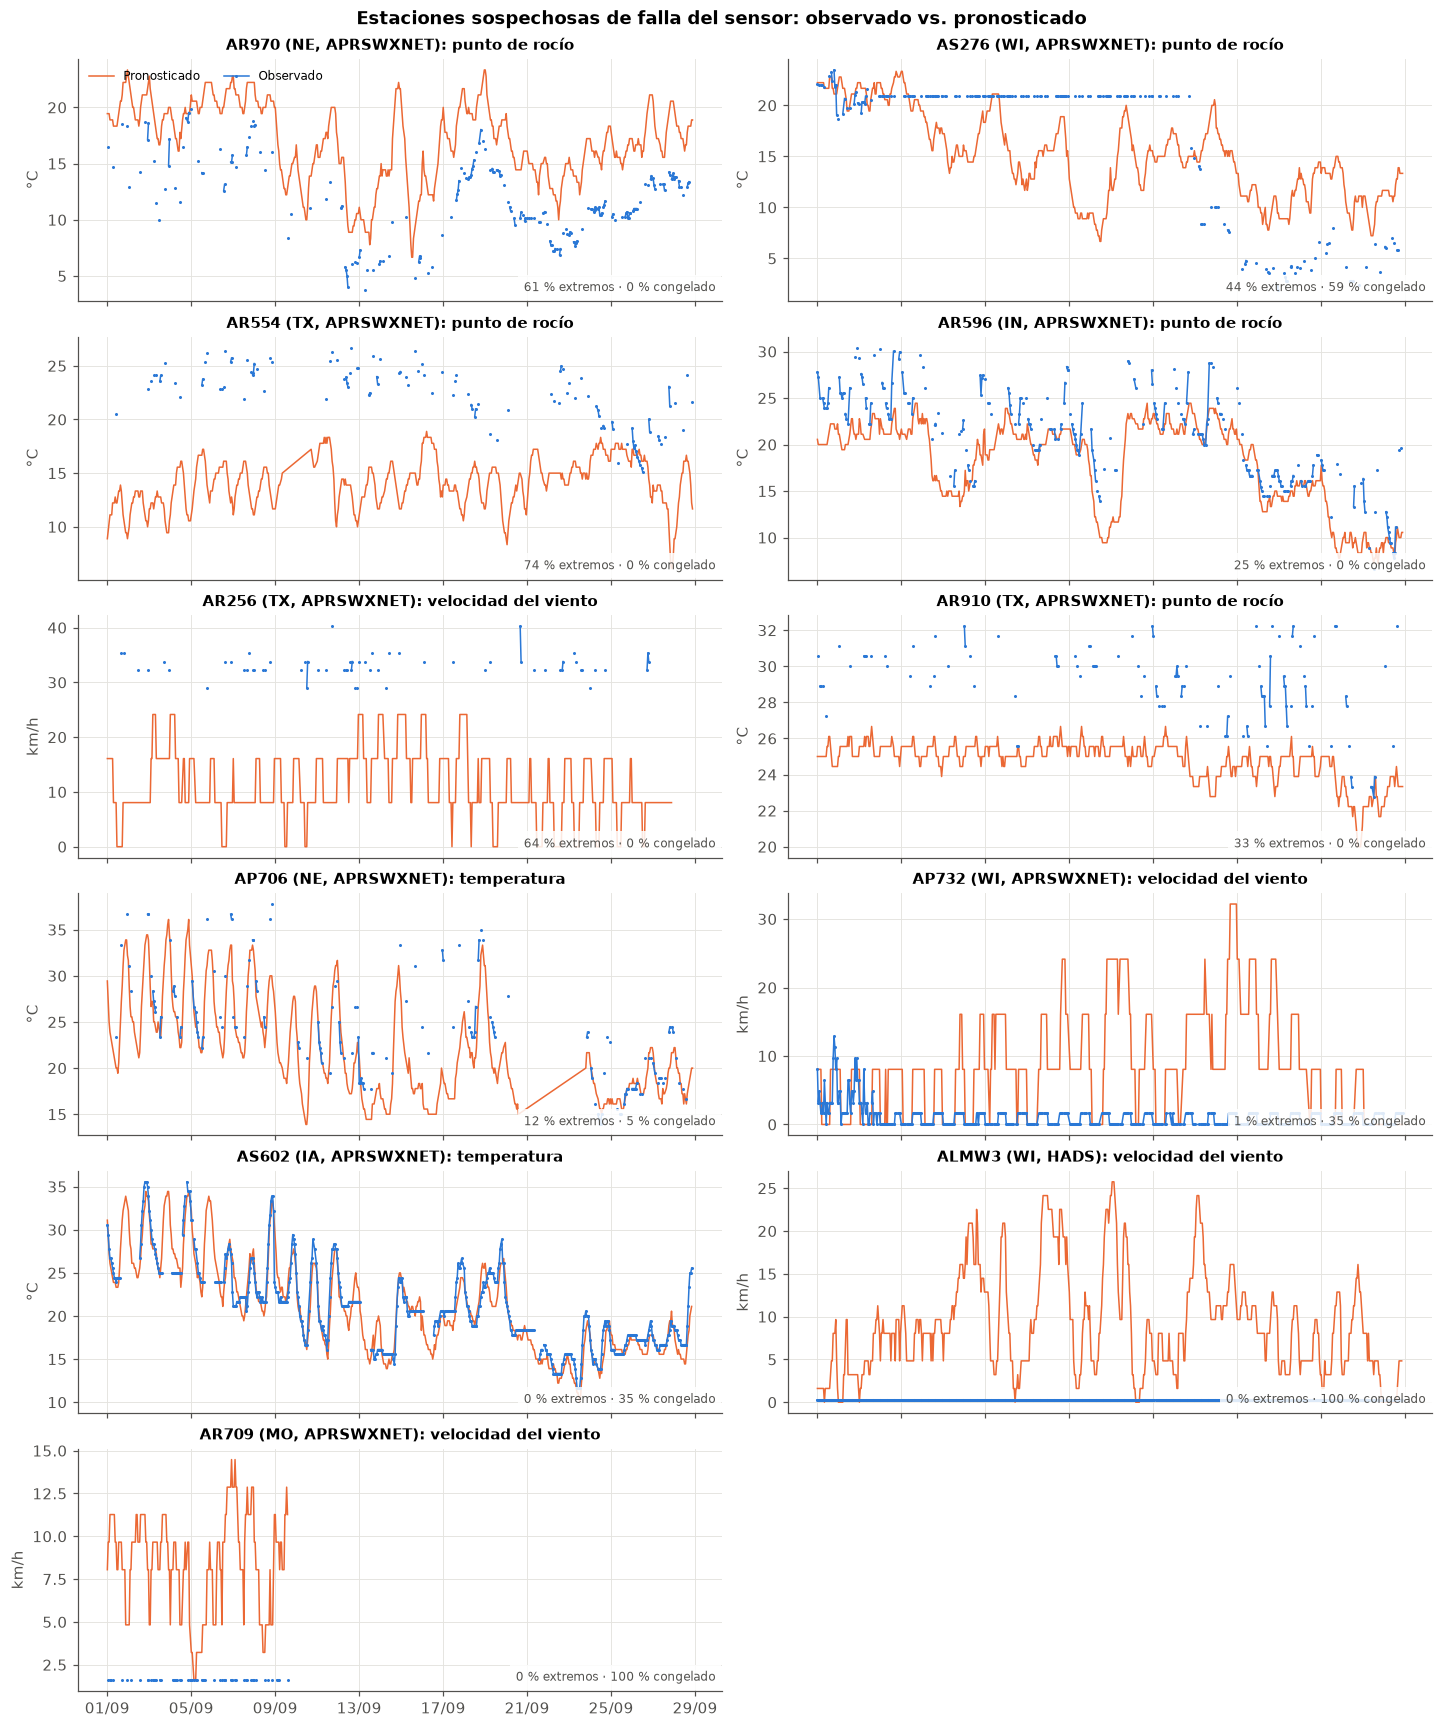

In [8]:
paneles = sospechosas.reset_index().sort_values('Extremos', ascending=False).drop_duplicates('station_id')
OBS_PRON = {nombre: (col.replace('error_', 'obs_'), col.replace('error_', 'fcst_'), unidad) for col, nombre, unidad in ERRORES}

filas_fig = int(np.ceil(len(paneles) / 2))
fig, axes = plt.subplots(filas_fig, 2, figsize=(13, 2.6 * filas_fig), sharex=True, constrained_layout=True)
for ax, (_, p) in zip(axes.flat, paneles.iterrows()):
    obs, pron, unidad = OBS_PRON[p['Variable']]
    d = mp[mp['station_id'] == p['station_id']]
    ax.plot(d['fcst_target_timestamp'], d[pron], color=NARANJA, lw=1, label='Pronosticado')
    ax.plot(d['fcst_target_timestamp'], d[obs], color=AZUL, lw=1, marker='.', ms=2, label='Observado')
    ax.set_title(f'{p["station_id"]} ({p["estado"]}, {p["red"]}): {p["Variable"].lower()}', fontsize=10)
    ax.set_ylabel(unidad)
    ax.text(0.99, 0.03, f'{p["% extremos"]:.0f} % extremos · {p["% congelado"]:.0f} % congelado',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=8, color=GRIS_TEXTO,
            bbox=dict(fc='white', ec='none', alpha=0.85))
for ax in axes.flat[len(paneles):]:
    ax.set_visible(False)
for ax in axes.flat:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
axes.flat[0].legend(loc='upper left', frameon=False, fontsize=8, ncol=2)
fig.suptitle('Estaciones sospechosas de falla del sensor: observado vs. pronosticado', fontweight='bold')
figuras['02_estaciones_sospechosas'] = fig
plt.show()

### Clasificación de cada error extremo

Para cada extremo se buscan las estaciones a 50 km o menos (distancia de gran círculo) que tienen dato de esa variable a
la misma hora, y se cuenta cuántas tienen también un extremo del mismo signo.

In [9]:
coords = mp.groupby('station_id')[['latitud', 'longitud']].first()
lat, lon = np.deg2rad(coords['latitud'].to_numpy()), np.deg2rad(coords['longitud'].to_numpy())
# Distancia de gran círculo (haversine) entre todos los pares de estaciones, en km
a = (np.sin((lat[:, None] - lat) / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat) * np.sin((lon[:, None] - lon) / 2) ** 2)
distancia = 2 * 6371 * np.arcsin(np.sqrt(a))
i, j = np.nonzero(distancia <= RADIO_KM)
vecinos = pd.DataFrame({'station_id': coords.index[i], 'vecino': coords.index[j]})[lambda v: v['station_id'] != v['vecino']]

CLASES = ['Valor congelado', 'Estación con falla persistente', 'Evento compartido', 'Aislado', 'Sin vecinos']
CLAVE = ['station_id', 'fcst_target_timestamp']
partes = []
for col, nombre, _ in ERRORES:
    obs, pron, _ = OBS_PRON[nombre]
    x = mp.loc[mp[f'extremo_{col}'], CLAVE + ['hora_local', 'estado', 'red', obs, pron, col,
                                             f'congelado_{col}', f'persistente_{col}']]
    # Vecinas con dato a la misma hora; las que tienen un extremo atribuible a su propio sensor no cuentan como evento
    otras = mp.loc[mp[col].notna(), CLAVE + [col]].rename(columns={'station_id': 'vecino', col: 'error_vecino'})
    otras['acompaña'] = (mp.loc[otras.index, f'extremo_{col}'] & ~mp.loc[otras.index, f'congelado_{col}']
                         & ~mp.loc[otras.index, f'persistente_{col}'])
    v = x[CLAVE + [col]].merge(vecinos, on='station_id').merge(otras, on=['vecino', 'fcst_target_timestamp'])
    v['acompaña'] &= np.sign(v['error_vecino']).eq(np.sign(v[col]))
    resumen = v.groupby(CLAVE).agg(**{'Vecinas con dato': ('vecino', 'size'), 'Vecinas con extremo': ('acompaña', 'sum')})
    x = x.merge(resumen, on=CLAVE, how='left').fillna({'Vecinas con dato': 0, 'Vecinas con extremo': 0})
    x['Clase'] = np.select([x[f'congelado_{col}'], x[f'persistente_{col}'], x['Vecinas con extremo'] > 0,
                            x['Vecinas con dato'] > 0], CLASES[:4], CLASES[4])
    partes.append(x.rename(columns={obs: 'Observado', pron: 'Pronosticado', col: 'Error'})
                  .drop(columns=[f'congelado_{col}', f'persistente_{col}']).assign(Variable=nombre))
extremos = pd.concat(partes, ignore_index=True)
extremos['Clase'] = pd.Categorical(extremos['Clase'], CLASES)
extremos[['Vecinas con dato', 'Vecinas con extremo']] = extremos[['Vecinas con dato', 'Vecinas con extremo']].astype(int)

tabla_clases = pd.crosstab(extremos['Variable'], extremos['Clase'], margins=True, margins_name='Total')
tabla_clases = tabla_clases.reindex([nombre for _, nombre, _ in ERRORES] + ['Total'])
tabla_clases

Clase,Valor congelado,Estación con falla persistente,Evento compartido,Aislado,Sin vecinos,Total
Variable,,,,,,
Temperatura,52,58,570,93,147,920
Humedad relativa,6,116,186,77,86,471
Punto de rocío,67,356,55,110,131,719
Velocidad del viento,10,39,28,16,29,122
Total,135,569,839,296,393,2232


Mismo resumen en porcentaje de los extremos de cada variable:

In [10]:
tabla_clases.div(tabla_clases['Total'], axis=0).mul(100).drop(columns='Total').round(1)

Clase,Valor congelado,Estación con falla persistente,Evento compartido,Aislado,Sin vecinos
Variable,,,,,
Temperatura,5.7,6.3,62.0,10.1,16.0
Humedad relativa,1.3,24.6,39.5,16.3,18.3
Punto de rocío,9.3,49.5,7.6,15.3,18.2
Velocidad del viento,8.2,32.0,23.0,13.1,23.8
Total,6.0,25.5,37.6,13.3,17.6


### Cuándo ocurren

Extremos por día y por clase. Los picos de **eventos compartidos** marcan días en que el pronóstico falló en muchas
estaciones a la vez; las fallas de sensor, en cambio, forman un fondo más o menos constante a lo largo del mes.

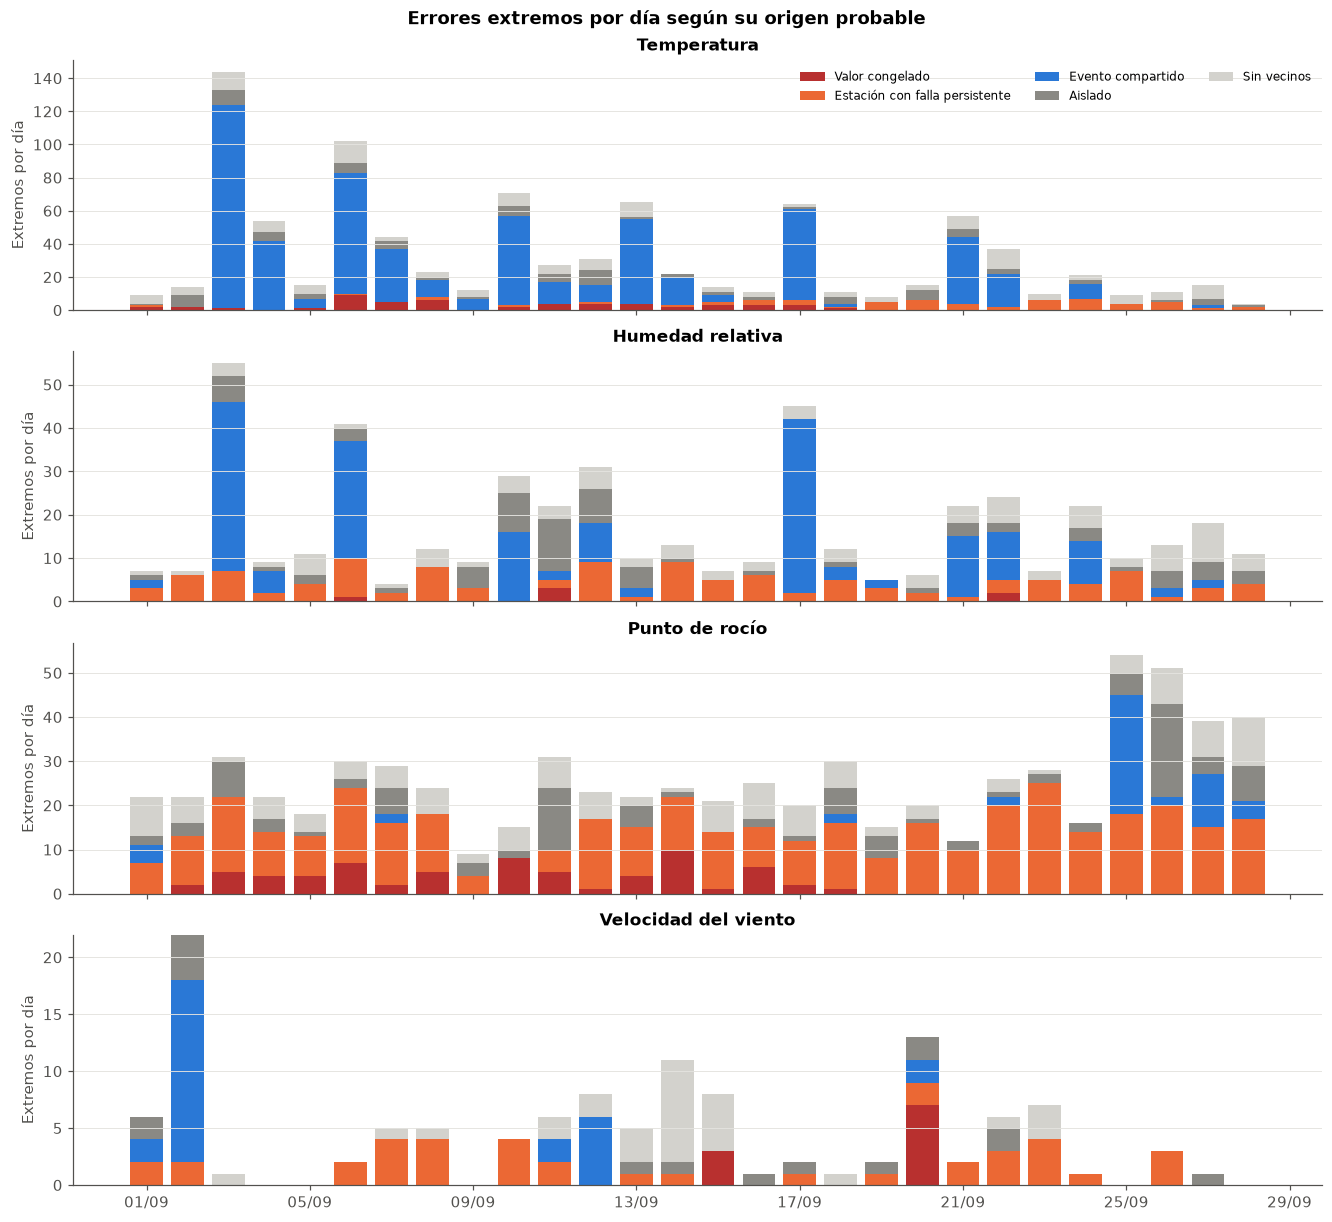

In [11]:
COLORES_CLASE = {'Valor congelado': '#b8302f', 'Estación con falla persistente': NARANJA,
                 'Evento compartido': AZUL, 'Aislado': '#8a8984', 'Sin vecinos': '#d3d2cd'}

extremos['Fecha'] = extremos['fcst_target_timestamp'].dt.tz_convert(None).dt.normalize()
dias = pd.date_range(extremos['Fecha'].min(), extremos['Fecha'].max(), freq='D')
fig, axes = plt.subplots(len(ERRORES), 1, figsize=(12, 11), sharex=True, constrained_layout=True)
for ax, (_, nombre, _) in zip(axes, ERRORES):
    conteo = (extremos[extremos['Variable'] == nombre].groupby(['Fecha', 'Clase']).size()
              .unstack(fill_value=0).reindex(index=dias, columns=CLASES, fill_value=0))
    base = np.zeros(len(dias))
    for clase in CLASES:
        ax.bar(dias, conteo[clase], bottom=base, width=0.8, color=COLORES_CLASE[clase], label=clase)
        base += conteo[clase].to_numpy()
    ax.set(title=nombre, ylabel='Extremos por día')
    ax.grid(axis='x', visible=False)
axes[0].legend(loc='upper right', frameon=False, fontsize=8, ncol=3)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
fig.suptitle('Errores extremos por día según su origen probable', fontweight='bold')
figuras['03_extremos_por_dia'] = fig
plt.show()

Horas con más estaciones en evento compartido (10 o más a la vez). La hora local es la mediana de las estaciones
involucradas.

In [12]:
compartidos = extremos[extremos['Clase'] == 'Evento compartido']
tabla_momentos = (compartidos.groupby(['Variable', 'fcst_target_timestamp'])
                  .agg(Estaciones=('station_id', 'size'),
                       Estados=('estado', lambda s: ', '.join(s.value_counts().index)),
                       Red=('red', lambda s: s.value_counts().index[0] if s.notna().any() else '—'),
                       **{'Hora local': ('hora_local', 'median'), 'Error mediano': ('Error', 'median')})
                  .reset_index()
                  .rename(columns={'fcst_target_timestamp': 'Hora UTC'})
                  .query('Estaciones >= 10')
                  .sort_values('Estaciones', ascending=False))
tabla_momentos['Hora UTC'] = tabla_momentos['Hora UTC'].dt.strftime('%d/%m %H:%M')
tabla_momentos.round(2)

,Variable,Hora UTC,Estaciones,Estados,Red,Hora local,Error mediano
60,Temperatura,03/09 20:00,49,"TX, MN",CENTERPOINT,15.0,7.38
61,Temperatura,03/09 21:00,40,"TX, MN",CENTERPOINT,16.0,7.56
114,Temperatura,17/09 21:00,37,TX,CENTERPOINT,16.0,6.35
71,Temperatura,06/09 19:00,34,TX,CENTERPOINT,14.0,6.49
70,Temperatura,06/09 18:00,22,TX,CENTERPOINT,13.0,6.55
59,Temperatura,03/09 19:00,22,"TX, IL",CENTERPOINT,14.0,6.93
120,Temperatura,21/09 23:00,22,"TX, LA",CENTERPOINT,18.0,7.47
22,Humedad relativa,17/09 21:00,22,TX,CENTERPOINT,16.0,-33.60
104,Temperatura,13/09 17:00,20,TX,CENTERPOINT,12.0,6.53
65,Temperatura,04/09 18:00,19,TX,CENTERPOINT,13.0,6.98


Condiciones pronosticadas y observadas en los eventos compartidos de temperatura, frente a todas las tardes (13 a 18 h
local) de la red CENTERPOINT, donde ocurren casi todos:

In [13]:
eventos_temp = mp.merge(compartidos.loc[compartidos['Variable'] == 'Temperatura', CLAVE], on=CLAVE)
tardes = mp[mp['red'].eq('CENTERPOINT') & mp['hora_local'].between(13, 18)]
COLUMNAS_EVENTO = {'fcst_pop_pct': 'PoP pronosticada (%)', 'fcst_temp_c': 'Temp. pron. (°C)', 'obs_temp_c': 'Temp. obs. (°C)',
                   'fcst_rh_pct': 'HR pron. (%)', 'obs_rh_pct': 'HR obs. (%)'}
pd.DataFrame({'Eventos compartidos de temperatura': eventos_temp[list(COLUMNAS_EVENTO)].median(),
              'Tardes de CENTERPOINT': tardes[list(COLUMNAS_EVENTO)].median()}).rename(index=COLUMNAS_EVENTO).round(1)

,Eventos compartidos de temperatura,Tardes de CENTERPOINT
PoP pronosticada (%),37.0,18.0
Temp. pron. (°C),32.8,32.8
Temp. obs. (°C),25.8,32.1
HR pron. (%),60.0,58.0
HR obs. (%),87.9,58.8


### Efecto de excluir las estaciones sospechosas

Sesgo, MAE y RMSE de cada variable con todas las estaciones y sin las estaciones sospechosas de esa variable
(las de la tabla anterior):

In [14]:
filas = {}
for col, nombre, _ in ERRORES:
    excluidas = sospechosas.xs(nombre, level='Variable').index if nombre in sospechosas.index.get_level_values('Variable') else []
    for etiqueta, e in [('Todas', mp[col]), ('Sin sospechosas', mp.loc[~mp['station_id'].isin(excluidas), col])]:
        e = e.dropna()
        filas[(nombre, etiqueta)] = {'Estaciones excluidas': len(excluidas) if etiqueta != 'Todas' else 0, 'n': len(e),
                                     'Sesgo': e.mean(), 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean())}
tabla_exclusion = pd.DataFrame(filas).T.astype({'Estaciones excluidas': int, 'n': int})
tabla_exclusion.round(2)

Estaciones excluidas       n  Sesgo  \
Temperatura          Todas                               0  186760   0.07   
                     Sin sospechosas                     3  185833   0.08   
Humedad relativa     Todas                               0  178718  -0.23   
                     Sin sospechosas                     6  177267  -0.22   
Punto de rocío       Todas                               0  180874  -0.01   
                     Sin sospechosas                     6  179369  -0.01   
Velocidad del viento Todas                               0  186015   2.93   
                     Sin sospechosas                     5  184322   2.89   

                                       MAE  RMSE  
Temperatura          Todas            1.08  1.48  
                     Sin sospechosas  1.08  1.47  
Humedad relativa     Todas            5.71  7.66  
                     Sin sospechosas  5.64  7.52  
Punto de rocío       Todas            0.93  1.29  
                     Sin sospechosas  0.92  1.23  
Velocidad del viento Todas            4.80  6.48  
                     Sin sospechosas  4.77  6.43

### Conclusiones

**Cuántos y de qué tipo.** Hay 2.232 errores extremos (0,3 % de los pares). Su origen depende mucho de la variable:

- **Temperatura**: el 62 % son **eventos compartidos**, es decir, fallas del modelo. Se concentran en unas pocas tardes
  (3, 6, 10, 13, 17 y 21/9, entre las 11 y las 18 h locales) en decenas de estaciones de CENTERPOINT (Houston) a la vez:
  el pronóstico dio ~33 °C y 60 % de HR y se observaron ~26 °C y 88 %. Es la firma de una tormenta de la tarde que
  enfría y humedece el aire. El modelo esperaba algo de lluvia (PoP mediana del 37 %, el doble de una tarde típica) pero
  no trasladó ese enfriamiento a la temperatura, lo que coincide con el sesgo cálido con PoP de 41–60 % de la fig. 05
  de `relaciones-bivariadas.ipynb`.
- **Humedad relativa**: los mismos eventos, con el signo opuesto (40 % compartidos), más las estaciones con el
  higrómetro fallado (25 %).
- **Punto de rocío**: al revés que la temperatura, el 59 % viene de **sensores** (congelados o con falla persistente) y
  solo el 8 % son eventos compartidos, la mitad el 25/9.
- **Viento**: 40 % de sensores y un único evento compartido grande, el 2/9.

**Estaciones con el sensor fallado.** Todas las sospechosas, salvo ALMW3 (HADS), son de **APRSWXNET**, la red de
aficionados. Lo que muestra la fig. 02:

- **Higrómetro descalibrado o saturado**: AR970 (NE) mide el rocío 5 °C por debajo del pronóstico todo el mes; AR554 (TX),
  8 a 12 °C por encima; AR596 (IN) y AR910 (TX) marcan rocío igual a la temperatura (HR del 100 %) gran parte del tiempo,
  típico de un sensor mojado.
- **Sensor trabado**: AS276 (WI) repite la misma temperatura y el mismo rocío del 4 al 17/9 y después mide valores muy
  por debajo del pronóstico. ALMW3, AR709 y AP732 reportan un viento fijo o casi nulo mientras el pronóstico varía.
- **Anemómetro defectuoso**: AR256 (TX) marca siempre entre 29 y 40 km/h, sin una sola calma.
- **Posible exposición al sol**: AP706 (NE) supera al pronóstico en los máximos diurnos.

**Impacto.** Excluir estas estaciones casi no cambia las métricas globales (son menos del 1 % de los pares; el RMSE del
rocío baja de 1,29 a 1,23 °C), así que las conclusiones de la secc. 8 de `relaciones-bivariadas.ipynb` se sostienen. Sí
pueden pesar en los análisis **por estación**, donde cada una es un punto con un error que no es del modelo: los mapas de
sesgo y MAE, y la relación entre el MAE y la elevación de la fig. 11, que ya estaba confundida con APRSWXNET. Conviene excluirlas (o marcarlas) en esos
análisis y en la Etapa B. La lista queda en `errores_extremos_clasificados.csv` y `tabla_estaciones_sospechosas.csv`.

**Limitaciones.** El 31 % de los extremos queda sin clasificar (aislados o sin vecinos): sin un registro de lluvia o radar
no se puede saber si una falla aislada es del sensor o una tormenta local. Los umbrales (3 RIC, 6 reportes repetidos,
10 % de extremos, 50 km) son heurísticos y cambiarlos mueve casos de una clase a otra.

## 4. Sesgo y MAE por estación

Cada punto es una estación con al menos 100 pares de esa variable (el mismo mínimo que la fig. 11 de
`relaciones-bivariadas.ipynb`). Se mapean dos medidas:

- **Sesgo** (media del error, pronosticado − observado), en una escala divergente centrada en 0: **rojo** donde el pronóstico
  **sobreestima** y azul donde subestima. Es el mismo criterio de color que la fig. 07 (allí el signo es observado −
  pronosticado, pero el rojo también indica sobreestimación).
- **MAE** (media del error absoluto), en una escala secuencial: más oscuro, más error.

Cada variable tiene su propia escala porque las unidades son distintas. La escala cubre hasta el P95 de las estaciones
(P5–P95 en el MAE) para que unas pocas estaciones extremas no la aplasten; los valores de afuera se pintan con el color del
borde de la escala. Las estaciones con **borde negro** son las sospechosas de falla del sensor en esa variable (secc. 3):
su color refleja el sensor más que el pronóstico, y no se usan para fijar la escala. Como en la fig. 07, el recuadro amplía
el área de Houston, donde se concentran las estaciones de CENTERPOINT, y los valores más extremos se dibujan encima.

In [15]:
N_MIN_ESTACION = 100
CRS_METRICO = 'EPSG:5070'  # el mismo de analisis_estaciones.ipynb y de la fig. 07

filas = []
for col, nombre, _ in ERRORES:
    g = mp[mp[col].notna()].groupby('station_id')
    t = pd.DataFrame({'Pares': g.size(), 'Sesgo': g[col].mean(), 'MAE': g[f'abs_{col}'].mean()})
    filas.append(t[t['Pares'] >= N_MIN_ESTACION].assign(Variable=nombre).reset_index())
error_estacion = pd.concat(filas, ignore_index=True).join(coords, on='station_id').join(atributos, on='station_id')
error_estacion['Sospechosa'] = pd.MultiIndex.from_frame(error_estacion[['station_id', 'Variable']]).isin(sospechosas.index)
error_estacion = gpd.GeoDataFrame(
    error_estacion, geometry=gpd.points_from_xy(error_estacion['longitud'], error_estacion['latitud']), crs='EPSG:4326'
).to_crs(CRS_METRICO).set_index(['Variable', 'station_id'])

estados_mapa = gpd.read_file(PROCESSED + 'estados_central.geojson').to_crs(CRS_METRICO)
houston = gpd.GeoSeries(gpd.points_from_xy([-96.25, -94.65], [29.3, 30.55]), crs='EPSG:4326').to_crs(CRS_METRICO)
print(error_estacion.groupby(level='Variable', sort=False)['Sospechosa'].agg(['size', 'sum'])
      .set_axis(['Estaciones', 'Sospechosas'], axis=1))

                      Estaciones  Sospechosas
Variable                                     
Temperatura                  334            3
Humedad relativa             325            6
Punto de rocío               324            6
Velocidad del viento         328            3


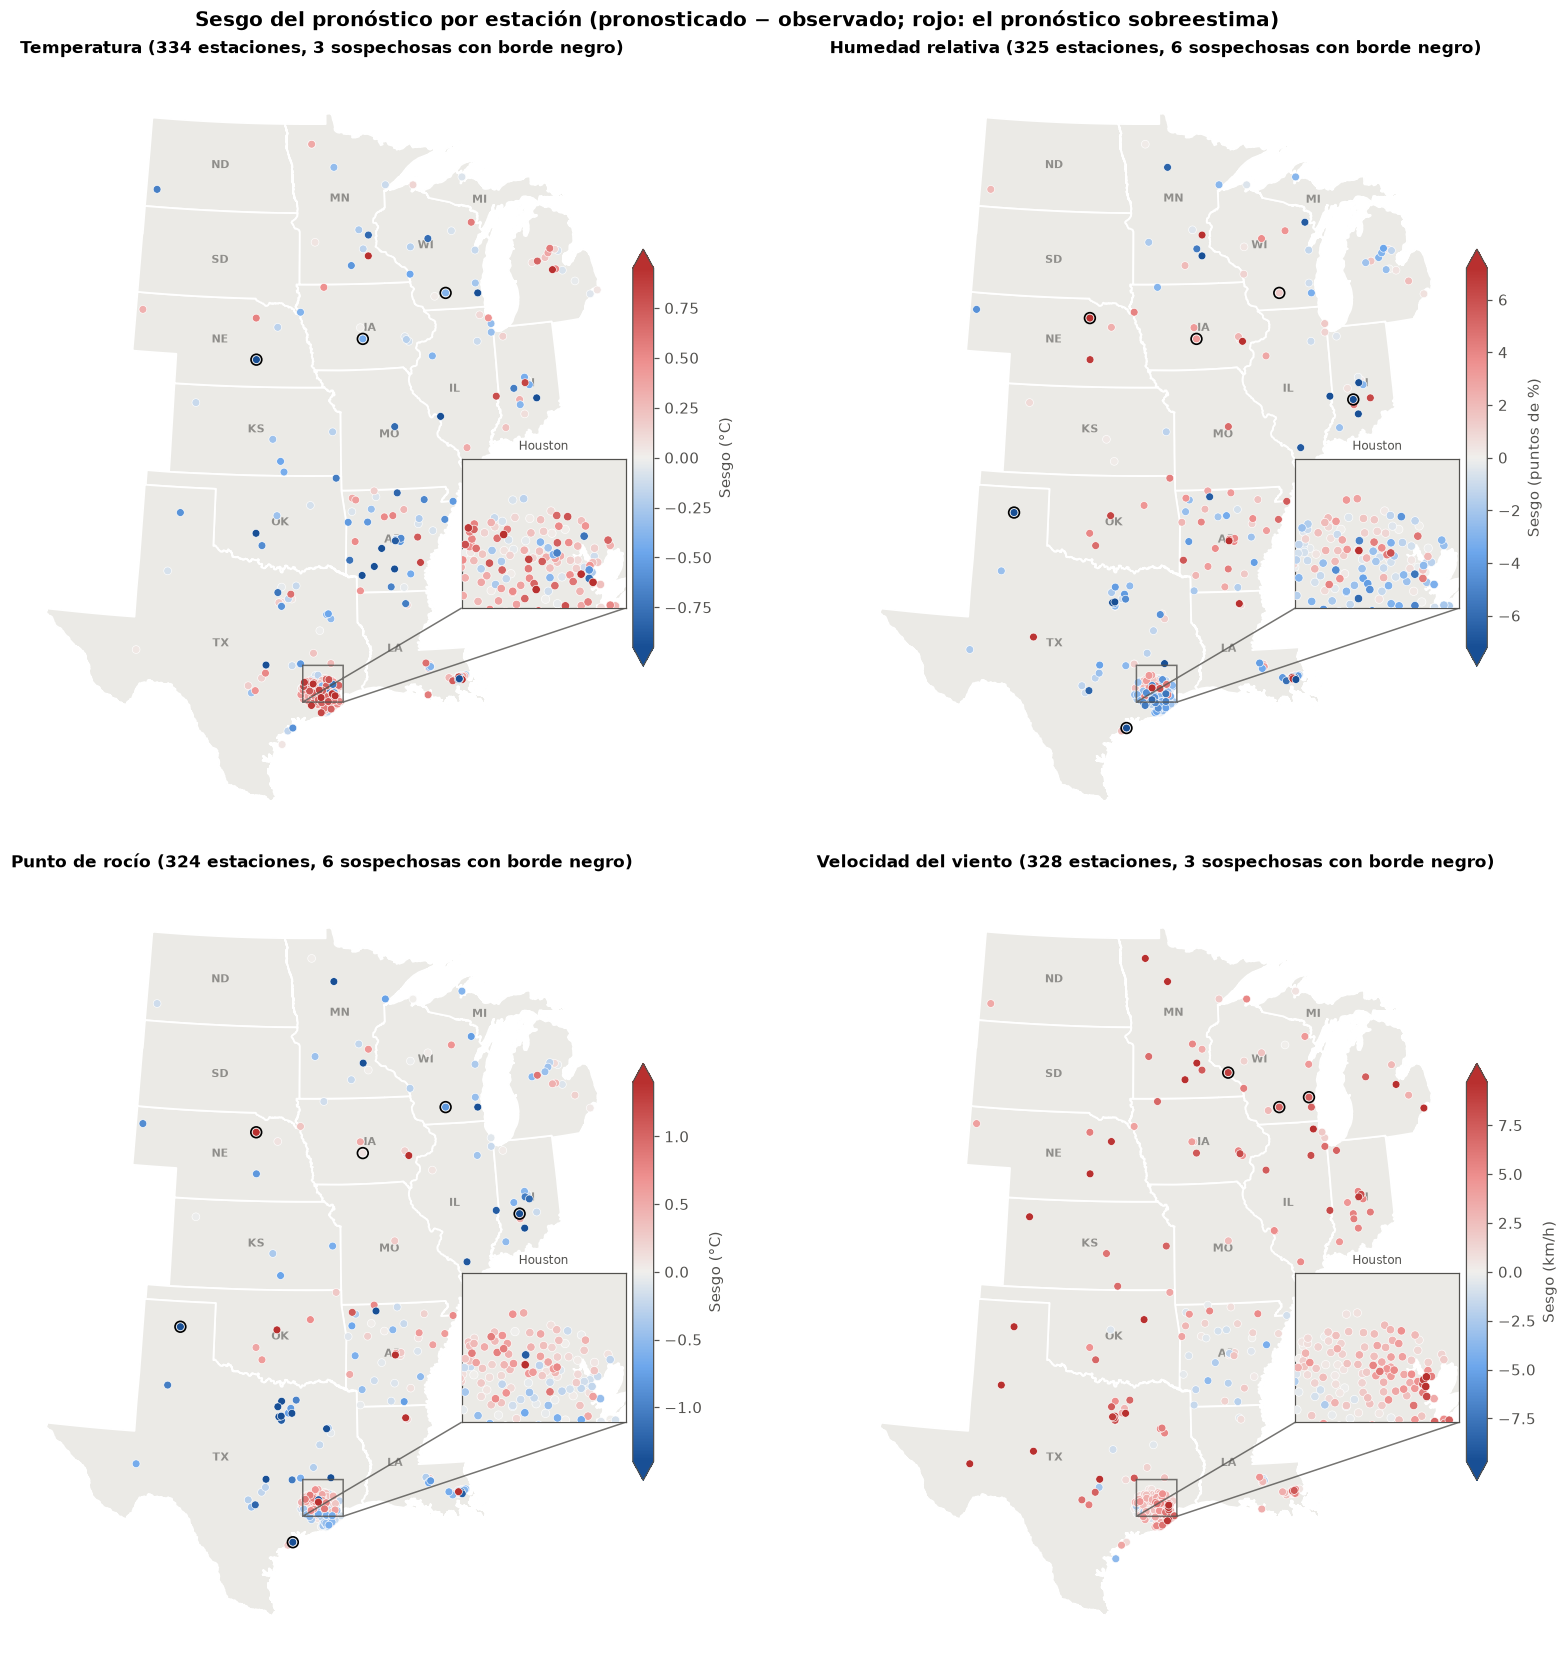

In [16]:
def mapa_estaciones(ax, d, medida, cmap, norma, titulo, etiqueta):
    """Mapa de una medida por estación, con las sospechosas de falla del sensor resaltadas y el recuadro de Houston."""
    d = d.loc[d[medida].abs().sort_values().index]  # los valores más extremos quedan encima
    sospechosa = d['Sospechosa']

    def dibujar(eje, tam):
        estados_mapa.plot(ax=eje, color='#ebeae6', edgecolor='white', linewidth=1.2)
        puntos = eje.scatter(d.geometry.x, d.geometry.y, c=d[medida], cmap=cmap, norm=norma, s=tam,
                             edgecolor='white', linewidth=0.4, zorder=3)
        eje.scatter(d.geometry.x[sospechosa], d.geometry.y[sospechosa], s=tam * 1.9, facecolor='none',
                    edgecolor='black', linewidth=1.1, zorder=4)
        return puntos

    puntos = dibujar(ax, 26)
    for _, fila in estados_mapa.iterrows():
        p = fila.geometry.representative_point()
        ax.annotate(fila['estado'], (p.x, p.y), ha='center', va='center', fontsize=7, color=GRIS_TEXTO,
                    fontweight='bold', alpha=0.6, zorder=2)

    axins = ax.inset_axes([0.73, 0.29, 0.27, 0.22])  # hueco al este de Arkansas, como en la fig. 07
    dibujar(axins, 30)
    axins.set_xlim(houston.x.min(), houston.x.max())
    axins.set_ylim(houston.y.min(), houston.y.max())
    axins.set_xticks([]), axins.set_yticks([])
    axins.set_xlabel(''), axins.set_ylabel('')  # geopandas rotula los ejes con las unidades del CRS
    axins.grid(False)
    for borde in axins.spines.values():
        borde.set_visible(True), borde.set_edgecolor(GRIS_TEXTO), borde.set_linewidth(0.8)
    axins.set_title('Houston', fontsize=8, fontweight='normal', color=GRIS_TEXTO)
    ax.indicate_inset_zoom(axins, edgecolor=GRIS_TEXTO, alpha=0.8)

    ax.figure.colorbar(puntos, ax=ax, shrink=0.55, pad=0.01, extend='both', label=etiqueta)
    ax.set_title(f'{titulo} ({len(d)} estaciones, {sospechosa.sum()} sospechosas con borde negro)')
    ax.set_axis_off()


def norma_sesgo(valores):
    """Escala divergente centrada en 0 hasta el P95 de |sesgo|, redondeado a 2 cifras significativas."""
    return CenteredNorm(vcenter=0, halfrange=float(f'{valores.abs().quantile(0.95):.2g}'))


def norma_mae(valores):
    """Escala secuencial entre el P5 y el P95 del MAE, redondeados a 2 cifras significativas."""
    p5, p95 = valores.quantile([0.05, 0.95])
    return Normalize(vmin=float(f'{p5:.2g}'), vmax=float(f'{p95:.2g}'))


def figura_mapas(medida, cmap, norma_de, titulo, nombre_figura):
    """Un mapa por variable; la escala se fija sin las estaciones sospechosas."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 15), constrained_layout=True)
    for ax, (_, nombre, unidad) in zip(axes.flat, ERRORES):
        d = error_estacion.xs(nombre, level='Variable')
        mapa_estaciones(ax, d, medida, cmap, norma_de(d.loc[~d['Sospechosa'], medida]), nombre, f'{medida} ({unidad})')
    fig.suptitle(titulo, fontweight='bold', fontsize=13)
    figuras[nombre_figura] = fig
    plt.show()


figura_mapas('Sesgo', DIVERGENTE, norma_sesgo,
             'Sesgo del pronóstico por estación (pronosticado − observado; rojo: el pronóstico sobreestima)',
             '04_mapa_sesgo_estacion')

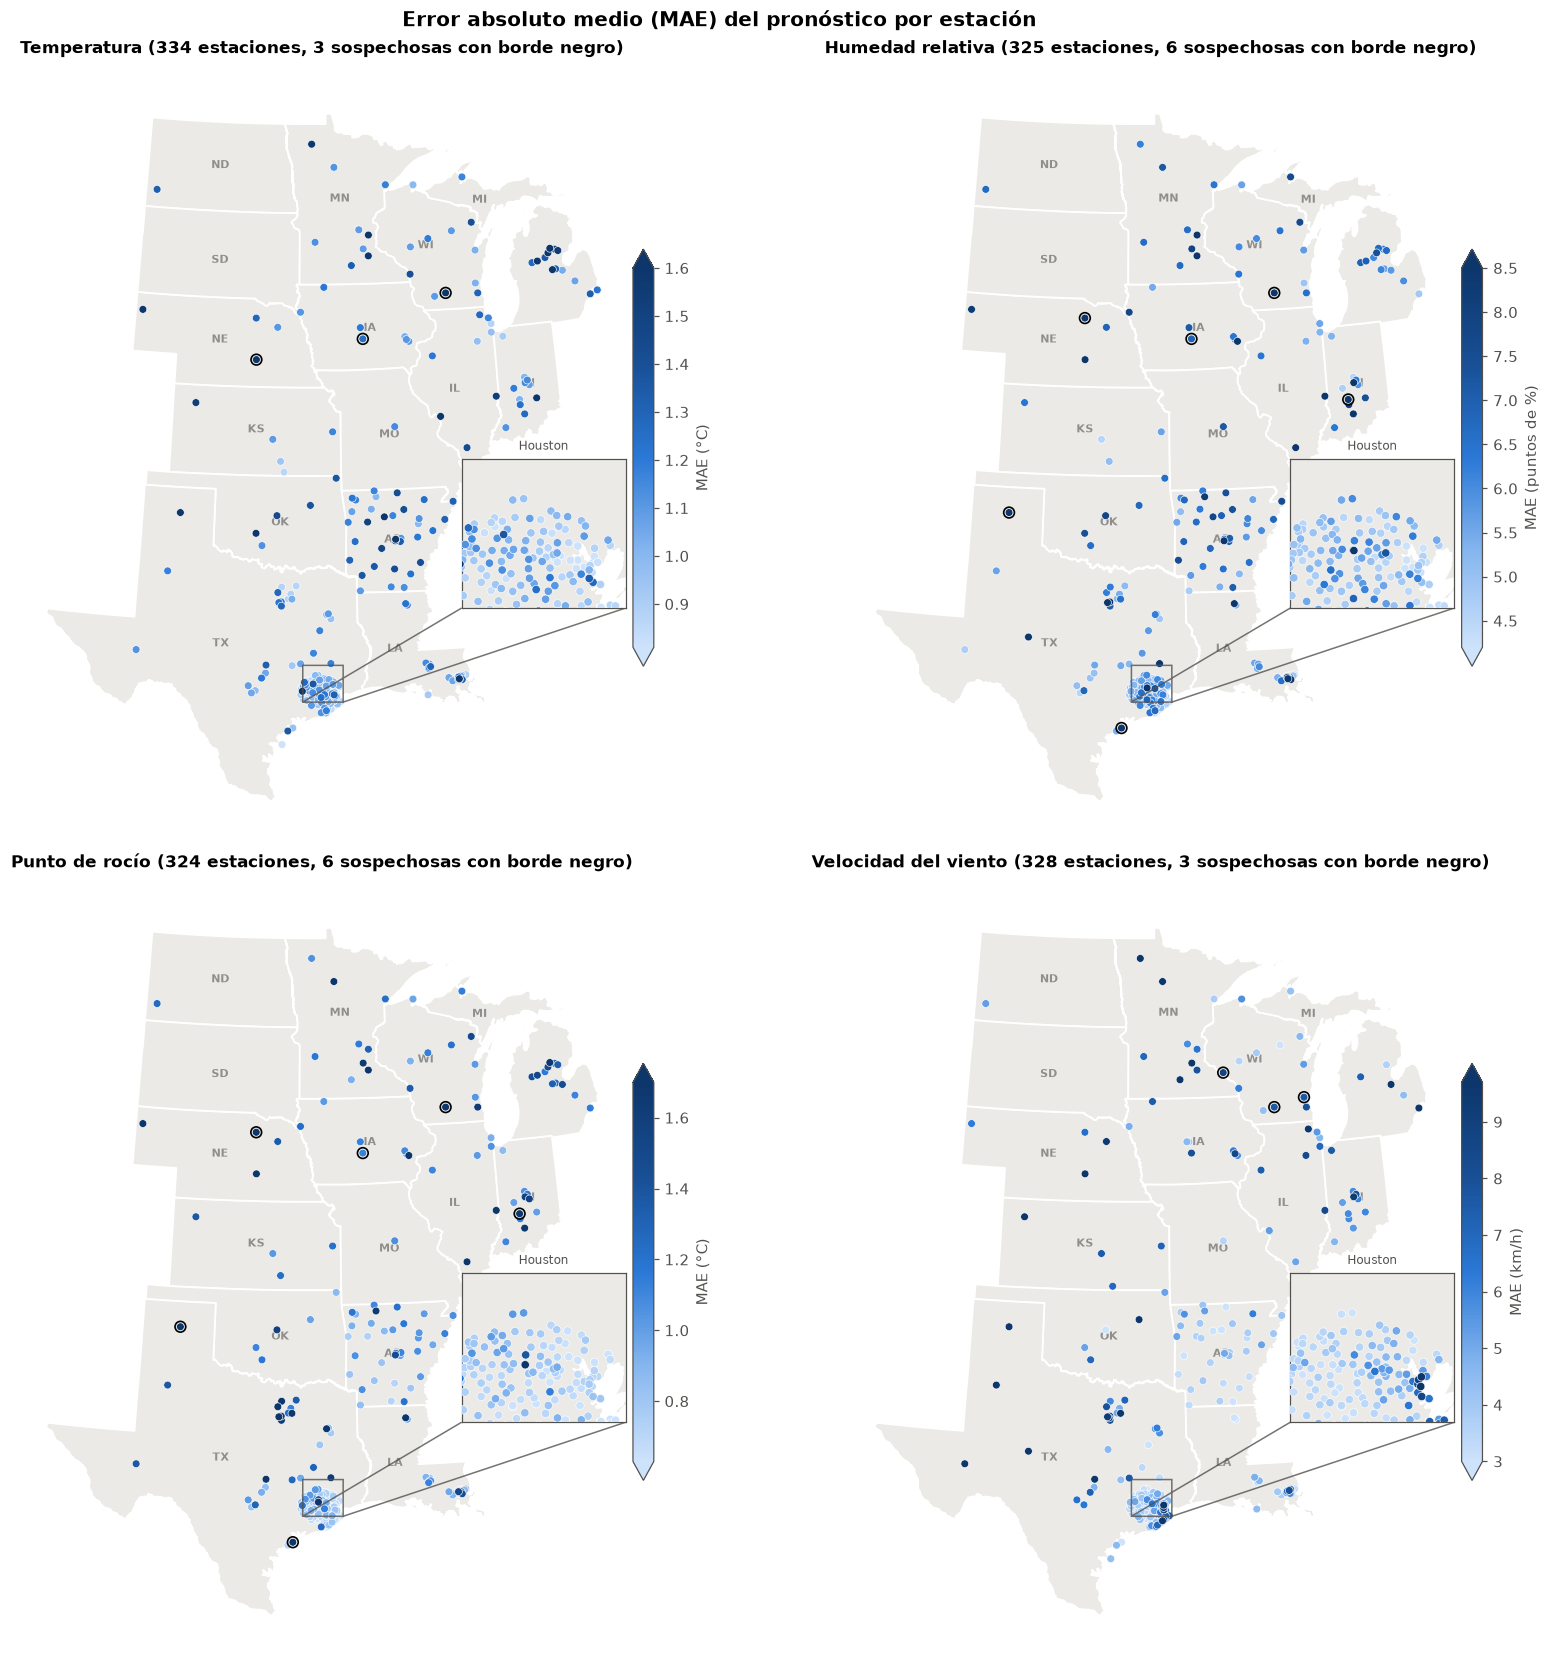

In [17]:
figura_mapas('MAE', SECUENCIAL, norma_mae, 'Error absoluto medio (MAE) del pronóstico por estación',
             '05_mapa_mae_estacion')

Resumen de las estaciones de cada variable, sin las sospechosas de falla del sensor. El sesgo regional (la media de
todos los pares, fig. 08) puede esconder estaciones con sesgos opuestos que se compensan: el % de estaciones que
sobreestiman y el rango P10–P90 muestran cuánto cambia de una estación a otra.

In [18]:
def resumen_estaciones(d):
    return pd.Series({
        'Estaciones': len(d),
        '% que sobreestiman': d['Sesgo'].gt(0).mean() * 100,
        'Sesgo P10': d['Sesgo'].quantile(0.1), 'Sesgo mediano': d['Sesgo'].median(), 'Sesgo P90': d['Sesgo'].quantile(0.9),
        'MAE P10': d['MAE'].quantile(0.1), 'MAE mediano': d['MAE'].median(), 'MAE P90': d['MAE'].quantile(0.9),
    })


confiables = error_estacion[~error_estacion['Sospechosa']]
tabla_mapas = pd.DataFrame({nombre: resumen_estaciones(confiables.xs(nombre, level='Variable'))
                            for _, nombre, _ in ERRORES}).T
tabla_mapas['Estaciones'] = tabla_mapas['Estaciones'].astype(int)
tabla_mapas.round(2)

,Estaciones,% que sobreestiman,Sesgo P10,Sesgo mediano,Sesgo P90,MAE P10,MAE mediano,MAE P90
Temperatura,331,56.50,-0.58,0.10,0.67,0.86,1.06,1.40
Humedad relativa,319,42.01,-4.19,-0.67,3.98,4.47,5.49,7.44
Punto de rocío,318,46.23,-0.75,-0.05,0.61,0.66,0.85,1.46
Velocidad del viento,325,84.62,-0.56,2.80,7.70,3.17,4.29,8.09


Sesgo y MAE medianos por red, para separar la geografía del tipo de estación (redes con al menos 10 estaciones en
la variable, sin las sospechosas):

In [19]:
por_red = (pd.DataFrame(confiables.drop(columns='geometry')).reset_index()
           .groupby(['Variable', 'red'])
           .agg(Estaciones=('station_id', 'size'), **{'Sesgo mediano': ('Sesgo', 'median'), 'MAE mediano': ('MAE', 'median')})
           .query('Estaciones >= 10')
           .reindex([nombre for _, nombre, _ in ERRORES], level='Variable'))
por_red.round(2)

Estaciones  Sesgo mediano  MAE mediano
Variable             red                                                
Temperatura          APRSWXNET            62          -0.08         1.15
                     ARDOT                28          -0.25         1.25
                     CENTERPOINT         148           0.30         0.95
                     RAWS                 12          -0.11         1.42
                     WEATHERSTEM          58          -0.14         1.06
Humedad relativa     APRSWXNET            58          -1.44         6.55
                     ARDOT                28           2.94         6.55
                     CENTERPOINT         147          -0.80         4.94
                     RAWS                 12           0.72         6.34
                     WEATHERSTEM          58           0.02         5.38
Punto de rocío       APRSWXNET            57          -0.48         1.30
                     ARDOT                28          -0.06         1.02
                     CENTERPOINT         147           0.10         0.73
                     RAWS                 12           0.02         1.08
                     WEATHERSTEM          58          -0.25         0.91
Velocidad del viento APRSWXNET            62           7.00         7.33
                     ARDOT                29          -0.34         3.84
                     CENTERPOINT         148           2.27         3.76
                     RAWS                 12           2.41         3.64
                     WEATHERSTEM          58           3.00         4.63

En el viento, las estaciones de CENTERPOINT del borde este de Houston (junto a la bahía de Galveston) se ven más rojas
que el resto. Se comparan sus calmas, su viento observado y pronosticado medio y su sesgo con el resto de la red:

In [20]:
viento_cp = mp[mp['red'].eq('CENTERPOINT')].dropna(subset=['obs_windspeed_kmh', 'fcst_windspeed_kmh'])
viento_cp = (viento_cp.groupby('station_id')
             .agg(longitud=('longitud', 'first'),
                  **{'% calmas': ('obs_windspeed_kmh', lambda s: s.eq(0).mean() * 100),
                     'Obs. media (km/h)': ('obs_windspeed_kmh', 'mean'),
                     'Pron. media (km/h)': ('fcst_windspeed_kmh', 'mean'),
                     'Sesgo (km/h)': ('error_windspeed_kmh', 'mean')}))
viento_cp['Zona'] = np.where(viento_cp['longitud'] > -95.1, 'Este (junto a la bahía)', 'Resto de Houston')
(viento_cp.groupby('Zona').median().drop(columns='longitud')
 .assign(Estaciones=viento_cp['Zona'].value_counts()).round(1))

,% calmas,Obs. media (km/h),Pron. media (km/h),Sesgo (km/h),Estaciones
Zona,,,,,
Este (junto a la bahía),6.4,4.9,11.3,5.4,26
Resto de Houston,10.2,4.6,6.5,2.0,122


### Conclusiones

**El error crece hacia el norte.** En las cuatro variables el MAE mediano por estación es más bajo en Texas y Luisiana que en
los estados del norte: en temperatura va de 0,96 °C en TX a 1,26–1,38 °C en MN, MI y OK; en punto de rocío, de 0,75 °C en TX a
1,23–1,33 °C en MN y MI; en viento, de 4,0 km/h en TX a 7,9 km/h en MN. Hay que leerlo con cuidado: Texas está dominado por
CENTERPOINT (148 estaciones en Houston, la red con menor MAE en temperatura, HR y rocío) y el norte tiene pocas estaciones y de
redes mezcladas, así que la geografía y la red están confundidas, como ya pasaba con la elevación en la fig. 11.

**Temperatura y HR se espejan.** Donde el pronóstico es cálido es también seco, y al revés: en Houston sobreestima la
temperatura (sesgo mediano de CENTERPOINT +0,30 °C) y subestima la HR (−0,80 puntos), mientras que en Arkansas (ARDOT) es
frío (−0,25 °C) y húmedo (+2,94 puntos). En esas dos redes el punto de rocío casi no tiene sesgo (+0,10 y −0,06 °C), lo
que sugiere que el pronóstico acierta la humedad absoluta y que el error de la HR viene sobre todo del de la temperatura.

**Punto de rocío sin patrón regional.** El sesgo por estación es chico (P10–P90 entre −0,75 y +0,61 °C) y sin zonas
definidas. De las 17 estaciones con un sesgo de más de 1,5 °C, 12 son de APRSWXNET y solo 4 están entre las sospechosas
de la secc. 3, lo que sugiere problemas de medición de la humedad en esa red más allá de los casos más evidentes.

**Viento: sobreestimación casi general.** El 85 % de las estaciones tiene sesgo positivo, y crece hacia el norte (mediana de
+2,5 km/h en TX y +7,5 km/h en MN), como en la fig. 07. Las excepciones son:

- **Arkansas** (ARDOT), prácticamente sin sesgo.
- **APRSWXNET**, con +7,0 km/h: es la red de aficionados que mide vientos muy bajos (secc. 3 de `relaciones-bivariadas.ipynb`).
- **El borde este de Houston**: el viento observado es como el del resto de la ciudad (4,9 contra 4,6 km/h), pero el pronóstico es un 75 % más alto (11,3 contra 6,5 km/h).
  Es probable que el pronóstico represente el viento sobre la bahía, que es más fuerte, y no el de estaciones en tierra
  protegidas por edificios y árboles. Es una limitación de la representatividad del pronóstico más que un sensor fallado.
  La excepción es 009CE, con 90 % de calmas, que sí parece un problema del sensor o del lugar.

**Zonas con mejores y peores pronósticos** (objetivo general del TP): el área de Houston tiene el menor error en temperatura,
HR y rocío, pero el viento se sobreestima en su borde costero. Los peores pronósticos están en el norte (MN, MI) para todas las
variables, y en Arkansas, Iowa y Oklahoma para la HR, donde el pronóstico es demasiado húmedo (+2,7 a +4,3 puntos).

## 5. Exportación de los gráficos y las tablas

In [21]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_forma.to_csv(OUT + 'tabla_forma_error.csv')
tabla_umbrales.to_csv(OUT + 'tabla_umbrales_extremos.csv')
sospechosas.to_csv(OUT + 'tabla_estaciones_sospechosas.csv')
tabla_clases.to_csv(OUT + 'tabla_clases_extremos.csv')
tabla_momentos.to_csv(OUT + 'tabla_momentos_extremos.csv', index=False)
tabla_exclusion.to_csv(OUT + 'tabla_efecto_exclusion.csv')
error_estacion.drop(columns='geometry').to_csv(OUT + 'tabla_error_por_estacion.csv')
tabla_mapas.to_csv(OUT + 'tabla_resumen_por_estacion.csv')
extremos.to_csv(OUT + 'errores_extremos_clasificados.csv', index=False)
print(f'Guardados {len(figuras)} gráficos, 8 tablas y la lista de extremos clasificados en {OUT}')

Guardados 5 gráficos, 8 tablas y la lista de extremos clasificados en ../data/out/distribucion/
